# Phase 4 — Final Multimodal Architecture & Fusion Comparison
**Weather-aware crop disease classification | Google Colab**

This single notebook builds on the Phase 2 manifest and Phase 3 baseline notebook. It compares:
- Image-only ConvNeXt-Tiny
- Image + weather concatenation
- Late fusion
- Gated fusion
- FiLM feature modulation

Default weather window: 7 days (`temp_mean_7d`, `humidity_mean_7d`, `rainfall_sum_7d`). You can switch to 1/3/14 days in Configuration. Weather statistics are fit on the training split only. Validation chooses checkpoints; the test set is evaluated only after training.

**Important scientific note:** Phase 2 contains aggregated overlapping weather windows, not a true day-by-day weather sequence. This notebook therefore compares window-level fusion methods; it does not claim to train a temporal weather transformer. Since Phase 2 notes that capture dates are largely the same, treat results as a controlled experiment, not proof of temporal generalization.

## 1. Setup and Drive paths
Run this notebook in Google Colab with a GPU runtime (`Runtime → Change runtime type → T4 GPU`).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os, json, time, random, copy, math, warnings
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, classification_report
)

PROJECT_ROOT = Path("/content/drive/MyDrive")
DATASET_ROOT = PROJECT_ROOT / "DATASET"
PHASE2_DIR = DATASET_ROOT / "docs" / "phase2_outputs"
OUTPUT_DIR = DATASET_ROOT / "docs" / "phase4_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Phase 2:", PHASE2_DIR)
print("Output:", OUTPUT_DIR)
print("Torch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Mounted at /content/drive
Phase 2: /content/drive/MyDrive/DATASET/docs/phase2_outputs
Output: /content/drive/MyDrive/DATASET/docs/phase4_outputs
Torch: 2.11.0+cu130 | CUDA: True
GPU: Tesla T4


## 2. Configuration

In [2]:
SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 24       # Lower to 8/16 if CUDA runs out of memory
NUM_WORKERS = 2
EPOCHS = 10           # Increase after validating the pipeline
PATIENCE = 3
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-4
PRETRAINED = True
FREEZE_BACKBONE = True
BACKBONE_NAME = "convnext_tiny"  # "efficientnet_b0" also supported

# Select one window: 1, 3, 7, or 14 days.
WEATHER_WINDOW_DAYS = 7
FUSION_MODELS = ["image_only", "concat", "late_fusion", "gated_fusion", "film"]
RUN_MODELS = FUSION_MODELS
USE_CLASS_WEIGHTS = True
MIXED_PRECISION = True

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if torch.cuda.is_available():
        torch.backends.cudnn.benchmark = True

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WINDOW_COLUMN_MAP = {
    1: ["temp_mean_1d", "humidity_mean_1d", "rainfall_sum_1d"],
    3: ["temp_mean_3d", "humidity_mean_3d", "rainfall_sum_3d"],
    7: ["temp_mean_7d", "humidity_mean_7d", "rainfall_sum_7d"],
    14: ["temp_mean_14d", "humidity_mean_14d", "rainfall_sum_14d"],
}
WEATHER_COLUMNS = WINDOW_COLUMN_MAP[WEATHER_WINDOW_DAYS]
print("Device:", device, "| Weather columns:", WEATHER_COLUMNS)

Device: cuda | Weather columns: ['temp_mean_7d', 'humidity_mean_7d', 'rainfall_sum_7d']


## 3. Load manifests and validate leakage groups

In [3]:
train_df = pd.read_csv(PHASE2_DIR / "multimodal_train.csv")
val_df   = pd.read_csv(PHASE2_DIR / "multimodal_val.csv")
test_df  = pd.read_csv(PHASE2_DIR / "multimodal_test.csv")

required = {"image_path", "label", "split_group", *WEATHER_COLUMNS}
for split_name, frame in [("train", train_df), ("val", val_df), ("test", test_df)]:
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{split_name} CSV is missing columns: {sorted(missing)}")
    if frame.empty:
        raise ValueError(f"{split_name} CSV is empty.")
    if frame[WEATHER_COLUMNS].isna().any().any():
        raise ValueError(f"Missing weather values in {split_name}; clean/impute Phase 2 data first.")

all_df = pd.concat([
    train_df.assign(_expected_split="train"),
    val_df.assign(_expected_split="val"),
    test_df.assign(_expected_split="test")
], ignore_index=True)

if "split" in all_df.columns:
    mismatch = (all_df["split"].astype(str) != all_df["_expected_split"]).sum()
    if mismatch:
        raise ValueError(f"{mismatch} rows have split labels inconsistent with their CSV file.")

if "split_group" in all_df.columns:
    group_splits = all_df.groupby("split_group")["_expected_split"].nunique()
    if (group_splits > 1).any():
        raise ValueError("Leakage check failed: split_group occurs across splits.")

class_names = sorted(train_df["label"].astype(str).unique().tolist())
label_to_idx = {name: i for i, name in enumerate(class_names)}
for name, frame in [("train", train_df), ("val", val_df), ("test", test_df)]:
    unknown = set(frame["label"].astype(str)) - set(class_names)
    if unknown:
        raise ValueError(f"{name} contains classes absent from training: {unknown}")
    frame["label_idx"] = frame["label"].astype(str).map(label_to_idx).astype(int)

print("Class count:", len(class_names))
print("Rows:", {"train": len(train_df), "val": len(val_df), "test": len(test_df)})
display(pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "val": val_df["label"].value_counts(),
    "test": test_df["label"].value_counts()
}).fillna(0).astype(int))

Class count: 4
Rows: {'train': 2245, 'val': 578, 'test': 654}


,train,val,test
label,,,
Black Rot,576,112,120
Esca,535,157,196
Healthy,664,207,238
Leaf Blight,470,102,100


## 4. Weather normalization (training split only)

In [4]:
weather_mean = train_df[WEATHER_COLUMNS].astype(float).mean()
weather_std = train_df[WEATHER_COLUMNS].astype(float).std().replace(0, 1).fillna(1)
normalization = {
    "weather_window_days": WEATHER_WINDOW_DAYS,
    "weather_columns": WEATHER_COLUMNS,
    "mean": weather_mean.to_dict(),
    "std": weather_std.to_dict(),
    "class_names": class_names,
    "seed": SEED,
}
(OUTPUT_DIR / f"normalization_{WEATHER_WINDOW_DAYS}d.json").write_text(json.dumps(normalization, indent=2))
display(pd.DataFrame({"mean": weather_mean, "std": weather_std}))

,mean,std
temp_mean_7d,27.888136,0.271227
humidity_mean_7d,68.552448,1.164107
rainfall_sum_7d,15.728102,0.387312


## 5. Image dataset and loaders

In [5]:
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(8),
    transforms.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.08),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

def resolve_image_path(value):
    p = Path(str(value))
    if p.is_absolute() and p.exists():
        return p
    candidate = DATASET_ROOT / p
    if candidate.exists():
        return candidate
    # Some manifests store paths relative to MyDrive.
    candidate = PROJECT_ROOT / p
    if candidate.exists():
        return candidate
    raise FileNotFoundError(f"Image path not found: {value}. Check DATASET_ROOT and Phase 2 image_path values.")

class CropWeatherDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        path = resolve_image_path(row["image_path"])
        with Image.open(path) as im:
            image = self.transform(im.convert("RGB"))
        weather = (row[WEATHER_COLUMNS].astype(float).values - weather_mean.values) / weather_std.values
        return image, torch.tensor(weather, dtype=torch.float32), torch.tensor(int(row["label_idx"]), dtype=torch.long)

train_ds = CropWeatherDataset(train_df, train_transform)
val_ds = CropWeatherDataset(val_df, eval_transform)
test_ds = CropWeatherDataset(test_df, eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

# Check a sample path and batch before a long run.
x_img, x_weather, x_y = next(iter(train_loader))
print("Batch:", x_img.shape, x_weather.shape, x_y.shape)

Batch: torch.Size([24, 3, 224, 224]) torch.Size([24, 3]) torch.Size([24])


## 6. Model architectures

The image encoder is pretrained ConvNeXt-Tiny (or EfficientNet-B0). Fusion strategies use the same encoder and weather inputs for a fairer comparison. The `late_fusion` model combines separate image/weather class logits; `gated_fusion` learns a sample-specific weighting; `film` conditions visual features with weather-derived scale and bias.

In [6]:
def build_image_encoder(name=BACKBONE_NAME, pretrained=PRETRAINED, freeze=FREEZE_BACKBONE):
    if name == "convnext_tiny":
        weights = models.ConvNeXt_Tiny_Weights.DEFAULT if pretrained else None
        net = models.convnext_tiny(weights=weights)
        feature_dim = net.classifier[2].in_features
        net.classifier = nn.Identity()
        encoder = net
    elif name == "efficientnet_b0":
        weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
        net = models.efficientnet_b0(weights=weights)
        feature_dim = net.classifier[1].in_features
        net.classifier = nn.Identity()
        encoder = net
    else:
        raise ValueError("BACKBONE_NAME must be 'convnext_tiny' or 'efficientnet_b0'")
    if freeze:
        for p in encoder.parameters():
            p.requires_grad = False
    return encoder, feature_dim

class WeatherEncoder(nn.Module):
    def __init__(self, input_dim, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64), nn.LayerNorm(64), nn.GELU(), nn.Dropout(0.15),
            nn.Linear(64, hidden), nn.LayerNorm(hidden), nn.GELU()
        )
    def forward(self, w):
        return self.net(w)

class MultimodalClassifier(nn.Module):
    def __init__(self, mode, num_classes, backbone_name=BACKBONE_NAME):
        super().__init__()
        self.mode = mode
        self.image_encoder, self.image_dim = build_image_encoder(backbone_name)
        self.weather_encoder = WeatherEncoder(len(WEATHER_COLUMNS), 128)
        self.weather_head = nn.Linear(128, num_classes)
        self.image_head = nn.Sequential(nn.Dropout(0.25), nn.Linear(self.image_dim, num_classes))
        self.fused_head = nn.Sequential(
            nn.LayerNorm(self.image_dim + 128), nn.Dropout(0.3),
            nn.Linear(self.image_dim + 128, 256), nn.GELU(), nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )
        self.gate = nn.Sequential(nn.Linear(self.image_dim + 128, 256), nn.GELU(), nn.Linear(256, 1), nn.Sigmoid())
        self.weather_to_image = nn.Linear(128, self.image_dim)
        self.film = nn.Linear(128, self.image_dim * 2)
        self.film_head = nn.Sequential(nn.LayerNorm(self.image_dim), nn.Dropout(0.3), nn.Linear(self.image_dim, num_classes))
        self.late_scale = nn.Parameter(torch.tensor(0.0))
    def forward(self, images, weather):
        image_features = self.image_encoder(images)
        if image_features.ndim > 2:
            image_features = torch.flatten(image_features, 1)
        image_logits = self.image_head(image_features)
        if self.mode == "image_only":
            return image_logits
        weather_features = self.weather_encoder(weather)
        weather_logits = self.weather_head(weather_features)
        if self.mode == "concat":
            return self.fused_head(torch.cat([image_features, weather_features], dim=1))
        if self.mode == "late_fusion":
            alpha = torch.sigmoid(self.late_scale)
            return alpha * image_logits + (1 - alpha) * weather_logits
        if self.mode == "gated_fusion":
            gate = self.gate(torch.cat([image_features, weather_features], dim=1))
            fused = gate * image_features
            # Project weather embedding to image feature dimensionality before adding.
            fused = fused + (1 - gate) * self.weather_to_image(weather_features)
            return self.film_head(fused)
        if self.mode == "film":
            gamma, beta = self.film(weather_features).chunk(2, dim=1)
            modulated = image_features * (1 + torch.tanh(gamma)) + beta
            return self.film_head(modulated)
        raise ValueError(f"Unknown fusion mode: {self.mode}")

## 7. Training loop, early stopping, and metrics

In [7]:
def class_weight_tensor(frame):
    counts = frame["label_idx"].value_counts().reindex(range(len(class_names)), fill_value=0).values.astype(np.float32)
    counts = np.maximum(counts, 1)
    weights = counts.sum() / (len(counts) * counts)
    return torch.tensor(weights, dtype=torch.float32, device=device)

criterion = nn.CrossEntropyLoss(weight=class_weight_tensor(train_df) if USE_CLASS_WEIGHTS else None)
amp_enabled = MIXED_PRECISION and device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)

def epoch_pass(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    losses, targets_all, preds_all = [], [], []
    for images, weather, targets in loader:
        images, weather, targets = images.to(device), weather.to(device), targets.to(device)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_enabled):
                logits = model(images, weather)
                loss = criterion(logits, targets)
            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
        losses.append(loss.detach().item() * targets.size(0))
        preds_all.extend(logits.argmax(1).detach().cpu().numpy().tolist())
        targets_all.extend(targets.detach().cpu().numpy().tolist())
    acc = accuracy_score(targets_all, preds_all)
    precision, recall, f1, _ = precision_recall_fscore_support(targets_all, preds_all, average="macro", zero_division=0)
    return {
        "loss": sum(losses) / max(1, len(loader.dataset)),
        "accuracy": acc, "precision_macro": precision,
        "recall_macro": recall, "macro_f1": f1,
        "targets": targets_all, "predictions": preds_all
    }

def fit_model(mode):
    seed_everything(SEED)
    model = MultimodalClassifier(mode, len(class_names)).to(device)
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    best_f1, bad_epochs = -1, 0
    best_state = None
    history = []
    checkpoint = OUTPUT_DIR / f"best_{mode}_{BACKBONE_NAME}_{WEATHER_WINDOW_DAYS}d.pt"
    start = time.time()
    for epoch in range(1, EPOCHS + 1):
        tr = epoch_pass(model, train_loader, optimizer)
        va = epoch_pass(model, val_loader)
        history.append({
            "model": mode, "epoch": epoch,
            "train_loss": tr["loss"], "train_accuracy": tr["accuracy"], "train_macro_f1": tr["macro_f1"],
            "val_loss": va["loss"], "val_accuracy": va["accuracy"], "val_macro_f1": va["macro_f1"]
        })
        print(f"{mode:14s} | epoch {epoch:02d}/{EPOCHS} | train loss {tr['loss']:.4f} acc {tr['accuracy']:.4f} F1 {tr['macro_f1']:.4f} | val loss {va['loss']:.4f} acc {va['accuracy']:.4f} F1 {va['macro_f1']:.4f}")
        if va["macro_f1"] > best_f1:
            best_f1, bad_epochs = va["macro_f1"], 0
            best_state = copy.deepcopy(model.state_dict())
            torch.save({
                "model_state_dict": best_state, "mode": mode,
                "class_names": class_names, "weather_columns": WEATHER_COLUMNS,
                "weather_mean": weather_mean.to_dict(), "weather_std": weather_std.to_dict(),
                "backbone": BACKBONE_NAME, "image_size": IMAGE_SIZE,
                "weather_window_days": WEATHER_WINDOW_DAYS, "seed": SEED
            }, checkpoint)
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                print("Early stopping.")
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    pd.DataFrame(history).to_csv(OUTPUT_DIR / f"history_{mode}_{WEATHER_WINDOW_DAYS}d.csv", index=False)
    elapsed = time.time() - start
    return model, checkpoint, history, elapsed

## 8. Train fusion variants

In [8]:
trained_models = {}
summary_rows = []
histories = {}

for mode in RUN_MODELS:
    print("\n" + "=" * 80 + "\nTraining:", mode)
    model, checkpoint, history, elapsed = fit_model(mode)
    trained_models[mode] = model
    histories[mode] = history
    summary_rows.append({
        "model": mode, "best_val_macro_f1": max(h["val_macro_f1"] for h in history),
        "best_val_accuracy": max(h["val_accuracy"] for h in history),
        "epochs_run": len(history), "training_seconds": round(elapsed, 1),
        "backbone": BACKBONE_NAME, "weather_window_days": WEATHER_WINDOW_DAYS
    })
    print("Checkpoint:", checkpoint)

phase4_training_summary = pd.DataFrame(summary_rows).sort_values("best_val_macro_f1", ascending=False)
phase4_training_summary.to_csv(OUTPUT_DIR / f"phase4_training_summary_{WEATHER_WINDOW_DAYS}d.csv", index=False)
display(phase4_training_summary)


Training: image_only
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 175MB/s]


image_only     | epoch 01/10 | train loss 1.3258 acc 0.4927 F1 0.4193 | val loss 1.2467 acc 0.7664 F1 0.6499
image_only     | epoch 02/10 | train loss 1.2154 acc 0.7140 F1 0.6307 | val loss 1.1395 acc 0.7734 F1 0.6677
image_only     | epoch 03/10 | train loss 1.1220 acc 0.7599 F1 0.6845 | val loss 1.0507 acc 0.7907 F1 0.6935
image_only     | epoch 04/10 | train loss 1.0457 acc 0.7764 F1 0.7132 | val loss 0.9738 acc 0.8028 F1 0.7147
image_only     | epoch 05/10 | train loss 0.9841 acc 0.7822 F1 0.7208 | val loss 0.9097 acc 0.8149 F1 0.7401
image_only     | epoch 06/10 | train loss 0.9274 acc 0.7911 F1 0.7343 | val loss 0.8512 acc 0.8183 F1 0.7431
image_only     | epoch 07/10 | train loss 0.8757 acc 0.7947 F1 0.7374 | val loss 0.8061 acc 0.8201 F1 0.7528
image_only     | epoch 08/10 | train loss 0.8345 acc 0.8049 F1 0.7600 | val loss 0.7640 acc 0.8218 F1 0.7585
image_only     | epoch 09/10 | train loss 0.8000 acc 0.8049 F1 0.7597 | val loss 0.7283 acc 0.8201 F1 0.7570
image_only     | ep

,model,best_val_macro_f1,best_val_accuracy,epochs_run,training_seconds,backbone,weather_window_days
4,film,0.833628,0.861592,10,462.6,convnext_tiny,7
1,concat,0.831374,0.861592,7,308.3,convnext_tiny,7
3,gated_fusion,0.829607,0.861592,10,470.2,convnext_tiny,7
0,image_only,0.765602,0.825260,10,1175.4,convnext_tiny,7
2,late_fusion,0.750874,0.802768,10,441.4,convnext_tiny,7


## 9. Final test evaluation (run only after model selection)

In [9]:
test_rows = []
test_predictions = {}
for mode, model in trained_models.items():
    metrics = epoch_pass(model, test_loader)
    test_predictions[mode] = metrics["predictions"]
    test_rows.append({
        "model": mode, "test_loss": metrics["loss"], "test_accuracy": metrics["accuracy"],
        "test_precision_macro": metrics["precision_macro"],
        "test_recall_macro": metrics["recall_macro"], "test_macro_f1": metrics["macro_f1"],
        "backbone": BACKBONE_NAME, "weather_window_days": WEATHER_WINDOW_DAYS, "seed": SEED
    })
    report = classification_report(
        metrics["targets"], metrics["predictions"],
        labels=list(range(len(class_names))), target_names=class_names,
        output_dict=True, zero_division=0
    )
    pd.DataFrame(report).T.to_csv(OUTPUT_DIR / f"classification_report_{mode}_{WEATHER_WINDOW_DAYS}d.csv")
    cm = confusion_matrix(metrics["targets"], metrics["predictions"], labels=list(range(len(class_names))))
    pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(
        OUTPUT_DIR / f"confusion_matrix_{mode}_{WEATHER_WINDOW_DAYS}d.csv"
    )

test_results = pd.DataFrame(test_rows).sort_values("test_macro_f1", ascending=False)
test_results.to_csv(OUTPUT_DIR / f"phase4_test_results_{WEATHER_WINDOW_DAYS}d.csv", index=False)
display(test_results)

,model,test_loss,test_accuracy,test_precision_macro,test_recall_macro,test_macro_f1,backbone,weather_window_days,seed
3,gated_fusion,0.413956,0.854740,0.828636,0.795863,0.799402,convnext_tiny,7,42
1,concat,0.358096,0.845566,0.810766,0.792576,0.798775,convnext_tiny,7,42
4,film,0.411944,0.827217,0.786990,0.778055,0.781835,convnext_tiny,7,42
0,image_only,0.731377,0.813456,0.759705,0.747099,0.743271,convnext_tiny,7,42
2,late_fusion,1.012773,0.772171,0.696580,0.708206,0.697778,convnext_tiny,7,42


## 10. Plot learning curves and confusion matrix

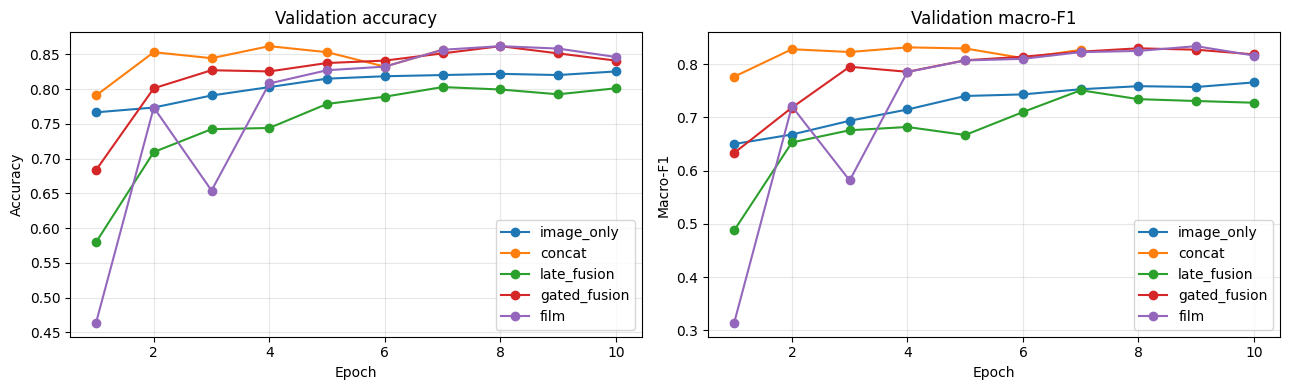

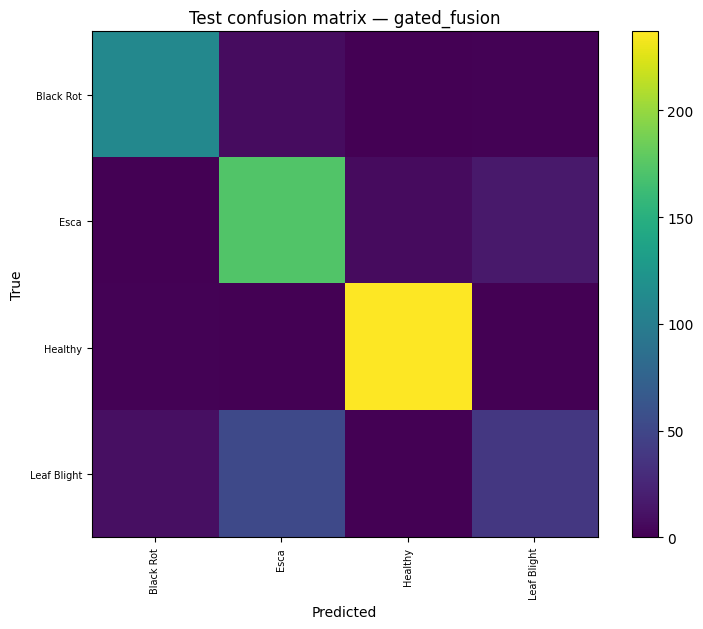

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for mode, hist in histories.items():
    h = pd.DataFrame(hist)
    axes[0].plot(h["epoch"], h["val_accuracy"], marker="o", label=mode)
    axes[1].plot(h["epoch"], h["val_macro_f1"], marker="o", label=mode)
axes[0].set_title("Validation accuracy"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
axes[1].set_title("Validation macro-F1"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Macro-F1")
for ax in axes: ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"phase4_validation_curves_{WEATHER_WINDOW_DAYS}d.png", dpi=160)
plt.show()

if len(test_results):
    best_mode = test_results.iloc[0]["model"]
    best_metrics = epoch_pass(trained_models[best_mode], test_loader)
    cm = confusion_matrix(best_metrics["targets"], best_metrics["predictions"], labels=list(range(len(class_names))))
    fig_w = max(8, min(18, len(class_names) * 0.45))
    plt.figure(figsize=(fig_w, fig_w * 0.8))
    plt.imshow(cm, interpolation="nearest")
    plt.title(f"Test confusion matrix — {best_mode}")
    plt.colorbar()
    ticks = np.arange(len(class_names))
    plt.xticks(ticks, class_names, rotation=90, fontsize=7)
    plt.yticks(ticks, class_names, fontsize=7)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"phase4_best_confusion_matrix_{WEATHER_WINDOW_DAYS}d.png", dpi=160)
    plt.show()

## 11. Weather reliance sanity checks

A model that uses weather should be tested when weather is shuffled or zeroed. This is a diagnostic, not a new training run. Large performance gains from weather may reflect real signal, but can also indicate dataset confounding; interpret with the Phase 2 split limitations in mind.

In [11]:
@torch.no_grad()
def evaluate_weather_perturbation(model, loader, perturbation="shuffle"):
    model.eval()
    ys, ps = [], []
    weather_bank = []
    if perturbation == "shuffle":
        for _, w, _ in loader:
            weather_bank.append(w)
        all_weather = torch.cat(weather_bank, dim=0)
        perm = torch.randperm(len(all_weather))
        perturbed_weather = all_weather[perm]
        offset = 0
    for images, weather, targets in loader:
        images, weather, targets = images.to(device), weather.to(device), targets.to(device)
        if perturbation == "zero":
            weather = torch.zeros_like(weather)
        elif perturbation == "shuffle":
            n = len(targets)
            weather = perturbed_weather[offset:offset+n].to(device)
            offset += n
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_enabled):
            logits = model(images, weather)
        ps.extend(logits.argmax(1).cpu().numpy().tolist())
        ys.extend(targets.cpu().numpy().tolist())
    return {
        "accuracy": accuracy_score(ys, ps),
        "macro_f1": precision_recall_fscore_support(ys, ps, average="macro", zero_division=0)[2]
    }

sanity_rows = []
for mode, model in trained_models.items():
    if mode == "image_only":
        continue
    for perturbation in ["normal", "shuffle", "zero"]:
        if perturbation == "normal":
            result = epoch_pass(model, test_loader)
            score = {"accuracy": result["accuracy"], "macro_f1": result["macro_f1"]}
        else:
            score = evaluate_weather_perturbation(model, test_loader, perturbation)
        sanity_rows.append({"model": mode, "weather_condition": perturbation, **score})
sanity_df = pd.DataFrame(sanity_rows)
sanity_df.to_csv(OUTPUT_DIR / f"weather_reliance_checks_{WEATHER_WINDOW_DAYS}d.csv", index=False)
display(sanity_df)

,model,weather_condition,accuracy,macro_f1
0,concat,normal,0.845566,0.798775
1,concat,shuffle,0.840979,0.793394
2,concat,zero,0.842508,0.795629
3,late_fusion,normal,0.772171,0.697778
4,late_fusion,shuffle,0.778287,0.709966
5,late_fusion,zero,0.790520,0.690965
6,gated_fusion,normal,0.854740,0.799402
7,gated_fusion,shuffle,0.847095,0.789861
8,gated_fusion,zero,0.833333,0.775725
9,film,normal,0.827217,0.781835


## 12. Run window ablations

To compare same-day, 3-day, 7-day and 14-day weather, change `WEATHER_WINDOW_DAYS` in Section 2 and rerun the notebook from Section 2 onward. Each run writes a separate results filename tagged with the selected window. Do not compare runs if the train/validation/test manifests or random seeds changed.

## Output files

Saved under `DATASET/docs/phase4_outputs/`:
- best model checkpoints (`best_*.pt`)
- per-model training histories
- test metrics CSV
- class-wise classification reports and confusion matrices
- validation curves and best-model confusion-matrix plot
- weather reliance sanity-check results
- weather normalization and run configuration metadata

## Research reporting checklist

- Report measured results only; do not insert expected/placeholder accuracy into the paper.
- Report macro-F1, precision, recall, accuracy, per-class metrics and confusion matrix.
- Repeat the final comparison with at least 3 seeds (preferably 5) before reporting mean ± standard deviation.
- Choose architecture using validation metrics; keep test results for final reporting.
- State that Phase 2 uses aggregated weather windows and document the capture-date/location limitation.